<a href="https://github.com/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m11-3-computing-the-line.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computing the line: by hand, in Excel, in Python

In [2]:
# Setup: libraries, colors, plotting helpers, and the North Ames data
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf

PURPLE, GOLD, GRAY = "#510C76", "#B07A00", "#6E6E6E"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
n = len(na)
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
xbar, ybar = x.mean(), y.mean()

plt.rcParams["figure.dpi"] = 110

## Five homes

To see every step, we take five of the 89 homes. Prices are in thousands of dollars to keep the numbers small.

In [ ]:
five = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/five_homes.csv")
five["price_k"] = five["price"] / 1000
five[["area", "price_k"]]

,area,price_k
0,922,116.0
1,928,132.0
2,1040,136.0
3,1109,139.0
4,1651,172.0


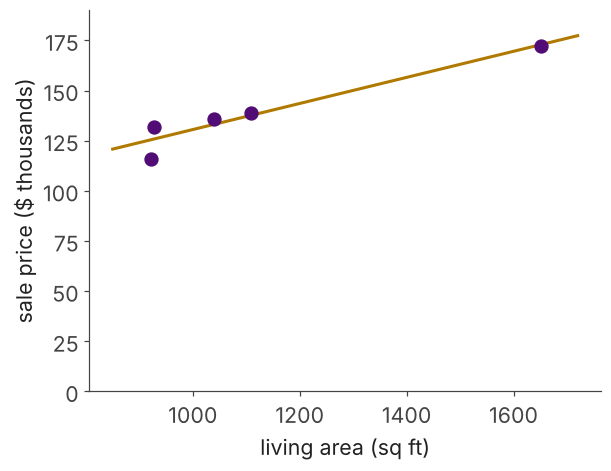

In [ ]:
# ---------------- 5. five homes for the hand calculation ----------------
five_fig = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/five_homes.csv")
fx, fy = five_fig.area.values.astype(float), five_fig.price.values / 1000
fa, fb = fit(fx, fy)
fig, ax = plt.subplots(figsize=(6, 4.5))
xx = np.linspace(850, 1720, 20)
ax.plot(xx, fa + fb * xx, color=GOLD, lw=2)
ax.scatter(fx, fy, color=PURPLE, s=70, zorder=3)
ax.set_ylim(0, 190); ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price ($ thousands)")
plt.show()  # f35_five_homes.png

## The calculation table

$\bar{x} = 5{,}650 / 5 = 1{,}130$ square feet and $\bar{y} = 695 / 5 = 139$ thousand dollars. The deviation columns each sum to zero, which is a useful check. We keep the squared deviations of $y$ for later.

| $x$ | $y$ | $x - \bar{x}$ | $y - \bar{y}$ | $(x - \bar{x})(y - \bar{y})$ | $(x - \bar{x})^2$ | $(y - \bar{y})^2$ |
|---:|---:|---:|---:|---:|---:|---:|
| 922 | 116 | −208 | −23 | 4,784 | 43,264 | 529 |
| 928 | 132 | −202 | −7 | 1,414 | 40,804 | 49 |
| 1,040 | 136 | −90 | −3 | 270 | 8,100 | 9 |
| 1,109 | 139 | −21 | 0 | 0 | 441 | 0 |
| 1,651 | 172 | 521 | 33 | 17,193 | 271,441 | 1,089 |
| $\bar{x}$ = 1,130 | $\bar{y}$ = 139 | 0 | 0 | $SS_{xy}$ = 23,661 | $SS_{xx}$ = 364,050 | $SS_{yy}$ = 1,676 |

## The line from five homes

$$b_1 = \frac{23{,}661}{364{,}050} = 0.0650 \qquad b_0 = 139 - 0.0650(1{,}130) = 65.56$$

$$\hat{y} = 65.56 + 0.0650x \quad (\$\text{ thousands})$$

That is about \$65 per square foot. With all 89 homes the line was $65{,}364 + 63.94x$, very close; five homes will not usually match this well.

## The same table in Excel

With area in column A and price in column B (rows 2 to 6), each column is one formula copied down. The dollar signs keep the mean fixed.

| Column | Formula in row 2, copied down |
|---|---|
| $x - \bar{x}$ | `=A2-AVERAGE($A$2:$A$6)` |
| $y - \bar{y}$ | `=B2-AVERAGE($B$2:$B$6)` |
| $(x - \bar{x})(y - \bar{y})$ | `=C2*D2` |
| $(x - \bar{x})^2$ | `=C2^2` |
| sums | `=SUM(E2:E6)`, and so on |
| check | `=SLOPE(B2:B6, A2:A6)` and `=INTERCEPT(B2:B6, A2:A6)` |

## The same table in Python

In [ ]:
x, y = five["area"], five["price_k"]
table = pd.DataFrame({"x": x, "y": y,
                      "x - xbar": x - x.mean(), "y - ybar": y - y.mean()})
table["product"] = table["x - xbar"] * table["y - ybar"]
table["(x - xbar)^2"] = table["x - xbar"] ** 2
table

,x,y,x - xbar,y - ybar,product,(x - xbar)^2
0,922,116.0,-208.0,-23.0,4784.0,43264.0
1,928,132.0,-202.0,-7.0,1414.0,40804.0
2,1040,136.0,-90.0,-3.0,270.0,8100.0
3,1109,139.0,-21.0,0.0,-0.0,441.0
4,1651,172.0,521.0,33.0,17193.0,271441.0


In [ ]:
ss_xy = table["product"].sum()
ss_xx = table["(x - xbar)^2"].sum()
b1 = ss_xy / ss_xx
b0 = y.mean() - b1 * x.mean()
print(f"SSxy = {ss_xy:,.0f}, SSxx = {ss_xx:,.0f}, b1 = {b1:.4f}, b0 = {b0:.2f}")

SSxy = 23,661, SSxx = 364,050, b1 = 0.0650, b0 = 65.56


## And with statsmodels, for all 89 homes

The formula `'price ~ area'` reads "price explained by area"; statsmodels adds the intercept by itself.

In [ ]:
from statsmodels.formula.api import ols

homes = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
model = ols("price ~ area", data=homes).fit()
model.params

Intercept    65364.147932
area            63.944944
dtype: float64